<a href="https://colab.research.google.com/github/ame60230/CS5720-HW-2/blob/main/HW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Aziz Erdogan

Question 1:

In [ ]:
import tensorflow as tf
import numpy as np

In [ ]:
#Downloads and loads the Shakespeare text dataset
path_to_file = tf.keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"
)

text = open(path_to_file, "rb").read().decode("utf-8")

print("Length of text:", len(text))
print("\nSample text:\n")
print(text[:500])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Length of text: 1115394

Sample text:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


In [ ]:
#Finds all unique characters in the text
vocab = sorted(set(text))

#Creates mappings between characters and numbers
char2idx = {char: index for index, char in enumerate(vocab)}
idx2char = np.array(vocab)

#Converts the entire text into integer values
text_as_int = np.array([char2idx[char] for char in text])

print("Number of unique characters:", len(vocab))
print("First 20 encoded characters:")
print(text_as_int[:20])

Number of unique characters: 65
First 20 encoded characters:
[18 47 56 57 58  1 15 47 58 47 64 43 52 10  0 14 43 44 53 56]


In [ ]:
#Number of characters used in each training sequence
seq_length = 100

#Creates a TensorFlow dataset from the encoded text
char_dataset = tf.data.Dataset.from_tensor_slices(text_as_int)

#Creates sequences of 101 characters
sequences = char_dataset.batch(
    seq_length + 1,
    drop_remainder=True
)

#Splits each sequence into input and target
def split_input_target(chunk):
    input_text = chunk[:-1]
    target_text = chunk[1:]
    return input_text, target_text

dataset = sequences.map(split_input_target)

#Shuffles and group sequences into batches
BATCH_SIZE = 64
BUFFER_SIZE = 10000

dataset = (
    dataset
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

#Displays the shape of one batch
for input_example, target_example in dataset.take(1):
    print("Input shape:", input_example.shape)
    print("Target shape:", target_example.shape)

Input shape: (64, 100)
Target shape: (64, 100)


In [ ]:
#Model settings
vocab_size = len(vocab)
embedding_dim = 128
rnn_units = 256

#Creates the LSTM-based RNN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(None,), dtype=tf.int32),

    tf.keras.layers.Embedding(
        vocab_size,
        embedding_dim
    ),

    tf.keras.layers.LSTM(
        rnn_units,
        return_sequences=True
    ),

    tf.keras.layers.Dense(vocab_size)
])

#Loss function
loss = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

#Compiles the model
model.compile(
    optimizer="adam",
    loss=loss
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 128)      │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 256)      │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 65)       │        16,705 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 419,265 (1.60 MB)

 Trainable params: 419,265 (1.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the model
history = model.fit(
    dataset,
    epochs=5
)

Epoch 1/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 117s 655ms/step - loss: 2.6817
Epoch 2/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 109s 623ms/step - loss: 2.1068
Epoch 3/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 110s 625ms/step - loss: 1.9303
Epoch 4/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 112s 639ms/step - loss: 1.8185
Epoch 5/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 111s 631ms/step - loss: 1.7411


In [ ]:
#Text generation function
def generate_text(
    model,
    start_string,
    num_generate=100,
    temperature=1.0
):
    input_eval = [
        char2idx[char]
        for char in start_string
    ]

    input_eval = tf.expand_dims(input_eval, 0)
    generated_text = []

    for i in range(num_generate):

        #Keeps only the latest 100 characters
        input_eval = input_eval[:, -100:]

        predictions = model(input_eval)
        predictions = predictions[:, -1, :]
        predictions = predictions / temperature

        predicted_id = tf.random.categorical(
            predictions,
            num_samples=1
        )[0, 0].numpy()

        input_eval = tf.concat(
            [input_eval, [[predicted_id]]],
            axis=1
        )

        generated_text.append(
            idx2char[predicted_id]
        )

    return start_string + "".join(generated_text)

In [ ]:
print("LOW TEMPERATURE (0.5):\n")

print(
    generate_text(
        model,
        start_string="ROMEO: ",
        num_generate=100,
        temperature=0.5
    )
)

print("\n" + "=" * 60 + "\n")

print("HIGH TEMPERATURE (1.5):\n")

print(
    generate_text(
        model,
        start_string="ROMEO: ",
        num_generate=100,
        temperature=1.5
    )
)

LOW TEMPERATURE (0.5):

ROMEO: I will the heart a pare,
And the well not be the words a man the faurtly and heart a dound son the p


HIGH TEMPERATURE (1.5):

ROMEO: I ary: and own? Frierviy, ourseep?
In me voust pares; aul himpht.
Rosa Hangitty castran, me soulty A


Temperature Scaling:
Temperature controls the amount of randomness used when selecting the next character during text generation. A lower temperature makes the model favor characters with higher predicted probabilities, producing more predictable and repetitive text. A higher temperature gives lower-probability characters a greater chance of being selected, which creates more varied and random text but may also produce less coherent results.

Question 2:

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

#Uses the 10,000 most common words
NUM_WORDS = 10000

#Loads the IMDB movie review dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.imdb.load_data(
        num_words=NUM_WORDS
    )
)

print("Number of training reviews:", len(x_train))
print("Number of test reviews:", len(x_test))

print("\nFirst review before padding:")
print(x_train[0][:50])

print("\nFirst review label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Number of training reviews: 25000
Number of test reviews: 25000

First review before padding:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447]

First review label: 1


In [ ]:
#Maximum number of words used from each review
MAX_LENGTH = 200

#Pad or truncate reviews so they all have the same length
x_train_padded = tf.keras.preprocessing.sequence.pad_sequences(
    x_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

x_test_padded = tf.keras.preprocessing.sequence.pad_sequences(
    x_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training data shape:", x_train_padded.shape)
print("Test data shape:", x_test_padded.shape)

print("\nFirst padded review:")
print(x_train_padded[0])

Training data shape: (25000, 200)
Test data shape: (25000, 200)

First padded review:
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480  284    5  150    4  172  112  167    2  336  385   39    4
  172 4536 1111   17  546   38   13  447    4  192   50   16    6  147
 2025   19   14   22    4 1920 4613  469    4   22   71   87   12   16
   43  530   38   76   15   13 1247    4   22   17  515   17   12   16
  626   18    2    5   62  386   12    8  316    8  106    5    4 2223
 5244   16  480   66 3785   33    4  130   12   16   38  619    5   25
  124   51   36  135   48   25 1415   33    6   22   12  215   28   77
   52    5   14  407   16   82    2    8    4  107  117 5952   15  256
    4    2    7 3766    5  723   36   71   43  530  476   26  400  317
   46    7    4    2 1029   13  104   88    4  381   15  297   98   32
 2071   56   26  141    6  194 7486   18    4  226   22   21  

In [ ]:
#Creates the LSTM sentiment classification model
sentiment_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAX_LENGTH,)),

    tf.keras.layers.Embedding(
        input_dim=NUM_WORDS,
        output_dim=128
    ),

    tf.keras.layers.LSTM(64),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

#Compiles the model
sentiment_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

sentiment_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the sentiment classifier
sentiment_history = sentiment_model.fit(
    x_train_padded,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 91s 281ms/step - accuracy: 0.5255 - loss: 0.6919 - val_accuracy: 0.5490 - val_loss: 0.6838
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 86s 276ms/step - accuracy: 0.6575 - loss: 0.6068 - val_accuracy: 0.7282 - val_loss: 0.5627
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 94s 300ms/step - accuracy: 0.7485 - loss: 0.5267 - val_accuracy: 0.6846 - val_loss: 0.6629


In [ ]:
#Evaluates the trained model on the test dataset
test_loss, test_accuracy = sentiment_model.evaluate(
    x_test_padded,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.6759764552116394
Test Accuracy: 0.6749200224876404


In [ ]:
#Predicts sentiment probabilities for the test reviews
prediction_probabilities = sentiment_model.predict(
    x_test_padded,
    verbose=0
).flatten()

#Converts probabilities into 0 or 1 predictions
y_pred = (
    prediction_probabilities >= 0.5
).astype(int)

print("First 20 predicted labels:")
print(y_pred[:20])

print("\nFirst 20 actual labels:")
print(y_test[:20])

First 20 predicted labels:
[0 1 1 0 1 1 0 1 1 1 0 0 1 0 1 0 1 0 0 0]

First 20 actual labels:
[0 1 1 0 1 1 1 0 0 1 1 0 0 0 1 0 1 0 0 0]


Confusion Matrix:
[[10181  2319]
 [ 5808  6692]]


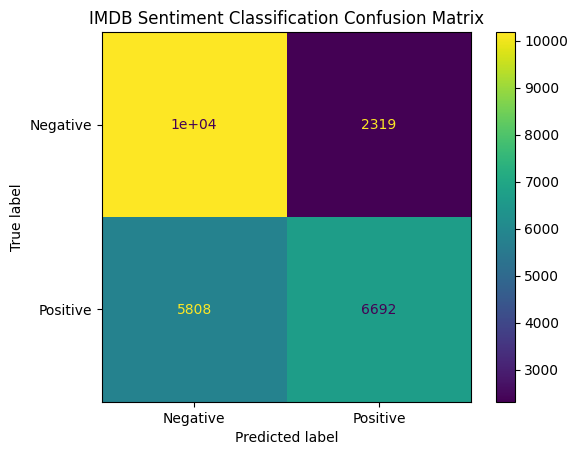

In [ ]:
#Create the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

#Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot()
plt.title("IMDB Sentiment Classification Confusion Matrix")
plt.show()

In [ ]:
#Print accuracy, precision, recall, and F1-score
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.64      0.81      0.71     12500
    Positive       0.74      0.54      0.62     12500

    accuracy                           0.67     25000
   macro avg       0.69      0.67      0.67     25000
weighted avg       0.69      0.67      0.67     25000



Precision-Recall Tradeoff:
Precision measures how often the model is correct when it predicts a review as positive, while recall measures how many of the actual positive reviews the model successfully identifies. Increasing the classification threshold can improve precision because the model becomes more selective, but it may lower recall by missing more positive reviews. Lowering the threshold can increase recall but may also produce more false positives. The appropriate balance depends on which type of classification error is more important for the application.

Question 3:

In [ ]:
import numpy as np
import tensorflow as tf

#Defines the 5x5 input matrix
input_matrix = np.array([
    [1,  2,  3,  4,  5],
    [6,  7,  8,  9, 10],
    [11, 12, 13, 14, 15],
    [16, 17, 18, 19, 20],
    [21, 22, 23, 24, 25]
], dtype=np.float32)

#Defines the 3x3 kernel
kernel = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

print("Input Matrix:")
print(input_matrix)

print("\nKernel:")
print(kernel)

Input Matrix:
[[ 1.  2.  3.  4.  5.]
 [ 6.  7.  8.  9. 10.]
 [11. 12. 13. 14. 15.]
 [16. 17. 18. 19. 20.]
 [21. 22. 23. 24. 25.]]

Kernel:
[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]


In [ ]:
#Reshape the input matrix for TensorFlow
#Shape becomes: (batch, height, width, channels)
input_tensor = tf.reshape(
    input_matrix,
    [1, 5, 5, 1]
)

#Reshape the kernel
#Shape becomes: (height, width, input_channels, output_channels)
kernel_tensor = tf.reshape(
    kernel,
    [3, 3, 1, 1]
)

print("Input Tensor Shape:", input_tensor.shape)
print("Kernel Tensor Shape:", kernel_tensor.shape)

Input Tensor Shape: (1, 5, 5, 1)
Kernel Tensor Shape: (3, 3, 1, 1)


In [ ]:
#Convolution with stride = 1 and VALID padding
output_valid_s1 = tf.nn.conv2d(
    input_tensor,
    kernel_tensor,
    strides=[1, 1, 1, 1],
    padding="VALID"
)

print("Stride = 1, Padding = VALID")
print(output_valid_s1.numpy().squeeze())

Stride = 1, Padding = VALID
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


In [ ]:
#Convolution with stride = 1 and SAME padding
output_same_s1 = tf.nn.conv2d(
    input_tensor,
    kernel_tensor,
    strides=[1, 1, 1, 1],
    padding="SAME"
)

print("Stride = 1, Padding = SAME")
print(output_same_s1.numpy().squeeze())

Stride = 1, Padding = SAME
[[  4.   3.   2.   1.  -6.]
 [ -5.   0.   0.   0. -11.]
 [-10.   0.   0.   0. -16.]
 [-15.   0.   0.   0. -21.]
 [-46. -27. -28. -29. -56.]]


In [ ]:
#Convolution with stride = 2 and VALID padding
output_valid_s2 = tf.nn.conv2d(
    input_tensor,
    kernel_tensor,
    strides=[1, 2, 2, 1],
    padding="VALID"
)

print("Stride = 2, Padding = VALID")
print(output_valid_s2.numpy().squeeze())

Stride = 2, Padding = VALID
[[0. 0.]
 [0. 0.]]


In [ ]:
#Convolution with stride = 2 and SAME padding
output_same_s2 = tf.nn.conv2d(
    input_tensor,
    kernel_tensor,
    strides=[1, 2, 2, 1],
    padding="SAME"
)

print("Stride = 2, Padding = SAME")
print(output_same_s2.numpy().squeeze())

Stride = 2, Padding = SAME
[[  4.   2.  -6.]
 [-10.   0. -16.]
 [-46. -28. -56.]]


In [ ]:
print("Stride = 1, Padding = VALID")
print(output_valid_s1.numpy().squeeze())

print("\nStride = 1, Padding = SAME")
print(output_same_s1.numpy().squeeze())

print("\nStride = 2, Padding = VALID")
print(output_valid_s2.numpy().squeeze())

print("\nStride = 2, Padding = SAME")
print(output_same_s2.numpy().squeeze())

Stride = 1, Padding = VALID
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

Stride = 1, Padding = SAME
[[  4.   3.   2.   1.  -6.]
 [ -5.   0.   0.   0. -11.]
 [-10.   0.   0.   0. -16.]
 [-15.   0.   0.   0. -21.]
 [-46. -27. -28. -29. -56.]]

Stride = 2, Padding = VALID
[[0. 0.]
 [0. 0.]]

Stride = 2, Padding = SAME
[[  4.   2.  -6.]
 [-10.   0. -16.]
 [-46. -28. -56.]]


Convolution Results:
With VALID padding, no extra values are added around the input, so the output feature map becomes smaller. With SAME padding, zeros are added around the input so more border positions can be processed. Increasing the stride from 1 to 2 also reduces the size of the output because the kernel moves two positions at a time instead of one.

Question 4:

Task 1:

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [ ]:
#Creates a sample grayscale image
sample_image = np.zeros((256, 256), dtype=np.uint8)

#Add some shapes so there are clear edges to detect
cv2.rectangle(sample_image, (40, 40), (120, 120), 255, -1)
cv2.circle(sample_image, (180, 80), 35, 180, -1)
cv2.line(sample_image, (40, 200), (220, 150), 255, 8)

#Save the sample image
cv2.imwrite("sample_image.png", sample_image)

#Load the image in grayscale
image = cv2.imread(
    "sample_image.png",
    cv2.IMREAD_GRAYSCALE
)

print("Image shape:", image.shape)

Image shape: (256, 256)


In [ ]:
#Define Sobel-X filter
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

#Define Sobel-Y filter
sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

print("Sobel-X Filter:")
print(sobel_x)

print("\nSobel-Y Filter:")
print(sobel_y)

Sobel-X Filter:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sobel-Y Filter:
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


In [ ]:
#Apply Sobel filters to the grayscale image
edges_x = cv2.filter2D(
    image,
    cv2.CV_64F,
    sobel_x
)

edges_y = cv2.filter2D(
    image,
    cv2.CV_64F,
    sobel_y
)

#Convert results to visible positive pixel values
edges_x = cv2.convertScaleAbs(edges_x)
edges_y = cv2.convertScaleAbs(edges_y)

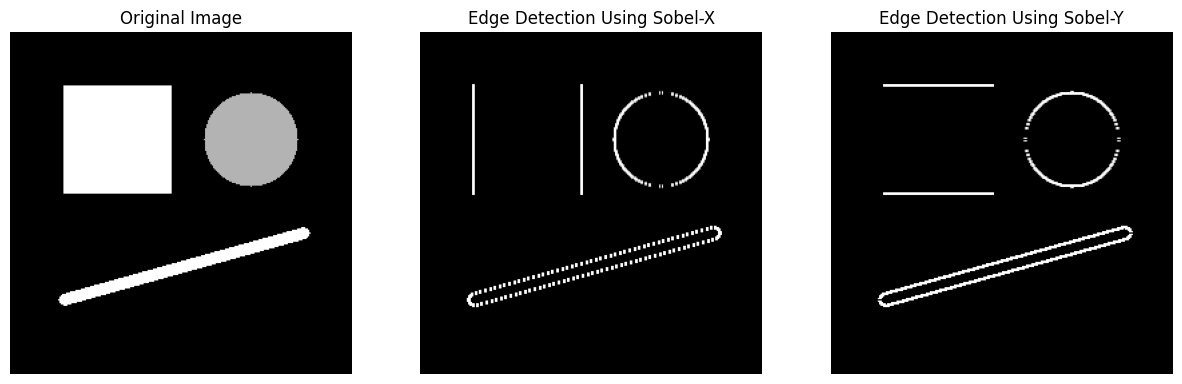

In [ ]:
#Display original image and Sobel edge detection results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(edges_x, cmap="gray")
plt.title("Edge Detection Using Sobel-X")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges_y, cmap="gray")
plt.title("Edge Detection Using Sobel-Y")
plt.axis("off")

plt.show()

Task 2:

In [ ]:
#Create a random 4x4 matrix
np.random.seed(42)

input_matrix = np.random.randint(
    1,
    10,
    size=(4, 4)
).astype(np.float32)

print("Original 4x4 Matrix:")
print(input_matrix)

Original 4x4 Matrix:
[[7. 4. 8. 5.]
 [7. 3. 7. 8.]
 [5. 4. 8. 8.]
 [3. 6. 5. 2.]]


In [ ]:
#Reshape matrix into TensorFlow image format
input_tensor = tf.reshape(
    input_matrix,
    [1, 4, 4, 1]
)

print("Tensor Shape:", input_tensor.shape)

Tensor Shape: (1, 4, 4, 1)


In [ ]:
#Create 2x2 Max Pooling layer
max_pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2)
)

#Create 2x2 Average Pooling layer
average_pool = tf.keras.layers.AveragePooling2D(
    pool_size=(2, 2)
)

#Apply pooling
max_pooled = max_pool(input_tensor)
average_pooled = average_pool(input_tensor)

#Remove unnecessary batch and channel dimensions
max_pooled_matrix = max_pooled.numpy().squeeze()
average_pooled_matrix = average_pooled.numpy().squeeze()

In [ ]:
print("Original Matrix:")
print(input_matrix)

print("\nMax-Pooled Matrix:")
print(max_pooled_matrix)

print("\nAverage-Pooled Matrix:")
print(average_pooled_matrix)

Original Matrix:
[[7. 4. 8. 5.]
 [7. 3. 7. 8.]
 [5. 4. 8. 8.]
 [3. 6. 5. 2.]]

Max-Pooled Matrix:
[[7. 8.]
 [6. 8.]]

Average-Pooled Matrix:
[[5.25 7.  ]
 [4.5  5.75]]


CNN Feature Extraction:
The Sobel-X and Sobel-Y filters detect edges in different directions by measuring changes in pixel intensity. Max pooling reduces the size of the input by keeping the largest value from each 2×2 region, while average pooling reduces the size by calculating the average value from each region.

Question 5:

Task 1:

In [ ]:
import tensorflow as tf

#Build a simplified AlexNet model
alexnet_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(227, 227, 3)),

    #Conv2D: 96 filters, 11x11 kernel, stride 4
    tf.keras.layers.Conv2D(
        96,
        kernel_size=(11, 11),
        strides=4,
        activation="relu"
    ),

    #Max Pooling: 3x3 pool, stride 2
    tf.keras.layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=2
    ),

    #Conv2D: 256 filters, 5x5 kernel
    tf.keras.layers.Conv2D(
        256,
        kernel_size=(5, 5),
        padding="same",
        activation="relu"
    ),

    #Max Pooling
    tf.keras.layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=2
    ),

    #Three convolution layers
    tf.keras.layers.Conv2D(
        384,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    tf.keras.layers.Conv2D(
        384,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    tf.keras.layers.Conv2D(
        256,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    #Final Max Pooling layer
    tf.keras.layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=2
    ),

    #Convert feature maps into a single vector
    tf.keras.layers.Flatten(),

    #Fully connected layer with 4096 neurons
    tf.keras.layers.Dense(
        4096,
        activation="relu"
    ),

    #Dropout 50%
    tf.keras.layers.Dropout(0.5),

    #Second fully connected layer
    tf.keras.layers.Dense(
        4096,
        activation="relu"
    ),

    #Dropout 50%
    tf.keras.layers.Dropout(0.5),

    #Output layer with 10 classes
    tf.keras.layers.Dense(
        10,
        activation="softmax"
    )
])

#Print model summary
alexnet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        40,970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,322,314 (222.48 MB)

 Trainable params: 58,322,314 (222.48 MB)

 Non-trainable params: 0 (0.00 B)

Task 2:

In [ ]:
#Define a residual block
def residual_block(input_tensor, filters):

    #First convolution layer
    x = tf.keras.layers.Conv2D(
        filters,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    )(input_tensor)

    #Second convolution layer
    x = tf.keras.layers.Conv2D(
        filters,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    )(x)

    #Skip connection:
    #Add the original input to the convolution output
    x = tf.keras.layers.Add()([
        x,
        input_tensor
    ])

    #Activation after the skip connection
    x = tf.keras.layers.ReLU()(x)

    return x

In [ ]:
#Input layer
inputs = tf.keras.layers.Input(
    shape=(32, 32, 3)
)

#Initial Conv2D layer:
#64 filters, 7x7 kernel, stride 2
x = tf.keras.layers.Conv2D(
    64,
    kernel_size=(7, 7),
    strides=2,
    padding="same",
    activation="relu"
)(inputs)

#Apply two residual blocks
x = residual_block(x, 64)
x = residual_block(x, 64)

#Flatten the feature maps
x = tf.keras.layers.Flatten()(x)

#Dense layer with 128 neurons
x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

#Softmax output layer
outputs = tf.keras.layers.Dense(
    10,
    activation="softmax"
)(x)

#Create the model
resnet_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Simple_ResNet"
)

#Print model summary
resnet_model.summary()

Model: "Simple_ResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │      9,472 │ input_layer_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │     36,928 │ conv2d_5[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 16,    │          0 │ conv2d_7[0][0],   │
│                     │ 64)               │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 16, 16,    │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │     36,928 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ conv2d_9[0][0],   │
│                     │ 64)               │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 16, 16,    │          0 │ add_1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 16384)     │          0 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │  2,097,280 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 10)        │      1,290 │ dense_5[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,255,754 (8.61 MB)

 Trainable params: 2,255,754 (8.61 MB)

 Non-trainable params: 0 (0.00 B)

CNN Architecture Comparison:
AlexNet uses a sequence of convolution, pooling, fully connected, and dropout layers to extract and classify image features. The ResNet-like model uses residual blocks with skip connections, which allow the original input of a block to be added back to its output. These skip connections help information pass through deeper networks more effectively.